# Lab 3: AI Programming Frameworks and Data Preparation
## Notebook 3: Feature Engineering and Data Preparation Pipeline

### Objectives:
1. Construct meaningful domain-specific engineered features.
2. Formulate proper separation between independent variables ($X$) and dependent target ($y$).
3. Implement train-test splitting with reproducible seeding (`random_state=42`) and stratification.
4. Prevent **Data Leakage**: Demonstrate why transformations must be fitted solely on training data.
5. Encode categorical variables using `OneHotEncoder`.
6. Scale numerical features using `StandardScaler`.
7. Perform feature correlation analysis with the target variable.
8. Evaluate statistical feature selection using ANOVA F-test (`f_classif`) and Mutual Information (`mutual_info_classif`).
9. Output final feature matrix shapes and export summary reports.

In [1]:
# 1. Essential Library Imports and Setup
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing and feature selection utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import f_classif, mutual_info_classif

# Configure style and paths
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
DATA_DIR = Path("datasets") if Path("datasets").exists() else Path("../datasets")
OUTPUT_DIR = Path("Lab3/outputs") if Path("Lab3").exists() else Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Data Directory  : {DATA_DIR.resolve()}")
print(f"Output Directory: {OUTPUT_DIR.resolve()}")

Data Directory  : /home/jeet/Desktop/Artificial_Intelligence/datasets
Output Directory: /home/jeet/Desktop/Artificial_Intelligence/Lab3/outputs


In [2]:
# 2. Dataset Loading and Initial Cleaning
dataset_path = DATA_DIR / "Placement_Data_Full_Class.csv"
if not dataset_path.exists():
    raise FileNotFoundError(f"Missing required dataset: {dataset_path}")

df = pd.read_csv(dataset_path)

# Drop irrelevant primary key identifier
if 'sl_no' in df.columns:
    df = df.drop(columns=['sl_no'])

print(f"Loaded dataset for feature engineering. Shape: {df.shape}")

Loaded dataset for feature engineering. Shape: (215, 14)


In [3]:
# 3. Domain-Specific Feature Creation
# Construct meaningful composite features capturing student academic trajectory:

# A. Composite Academic Average across 10th, 12th, and Undergrad
df['academic_avg'] = (df['ssc_p'] + df['hsc_p'] + df['degree_p']) / 3.0

# B. Academic Consistency: Standard deviation across the 3 educational stages (lower = more consistent)
df['academic_consistency'] = df[['ssc_p', 'hsc_p', 'degree_p']].std(axis=1)

# C. Post-Grad to Undergrad Ratio: Evaluates improvement in MBA compared to Undergrad degree
df['pg_ug_ratio'] = df['mba_p'] / df['degree_p']

# D. High Achiever Flag: Binary indicator for students maintaining >= 70% across all educational tiers
df['high_achiever'] = ((df['ssc_p'] >= 70) & (df['hsc_p'] >= 70) & (df['degree_p'] >= 70)).astype(int)

print("Created 4 new engineered features:")
display(df[['academic_avg', 'academic_consistency', 'pg_ug_ratio', 'high_achiever']].head())

Created 4 new engineered features:


,academic_avg,academic_consistency,pg_ug_ratio,high_achiever
0,72.000000,17.058722,1.013793,0
1,78.380000,0.926013,0.855447,1
2,65.666667,2.081666,0.903125,0
3,53.333333,2.309401,1.142885,0
4,77.566667,7.131853,0.757162,1


In [4]:
# 4. Separation of Independent Features (X) and Dependent Target (y)
# Target: 'status' ('Placed' -> 1, 'Not Placed' -> 0)
y = (df['status'] == 'Placed').astype(int)

# CRITICAL DATA LEAKAGE PREVENTION:
# 'salary' must be dropped from feature matrix X because salary is determined ONLY AFTER a candidate is placed.
# Including salary would result in near-perfect artificial prediction accuracy (severe data leakage).
features_to_drop = ['status', 'salary']
X = df.drop(columns=features_to_drop)

print("Target distribution:")
display(y.value_counts(normalize=True).round(3) * 100)
print(f"Features matrix shape: {X.shape}")
print(f"Target vector shape  : {y.shape}")

Target distribution:


status
1    68.8
0    31.2
Name: proportion, dtype: float64

Features matrix shape: (215, 16)
Target vector shape  : (215,)


In [5]:
# 5. Train-Test Split with Stratification and Reproducible Seed
# Splitting before fitting any scaler or encoder prevents information leakage from test set to training set
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape : {X_test.shape}, y_test shape : {y_test.shape}")
print(f"Train Placed ratio: {y_train.mean():.3f}")
print(f"Test Placed ratio : {y_test.mean():.3f}")

X_train shape: (172, 16), y_train shape: (172,)
X_test shape : (43, 16), y_test shape : (43,)
Train Placed ratio: 0.686
Test Placed ratio : 0.698


### Data Leakage and the Preprocessing Rule

> **Important Concept: Data Leakage Prevention**
>
> Data leakage occurs when information from outside the training dataset (such as future observations or test set statistics) is used to create or tune a machine learning pipeline.
>
> If we fit a scaler (e.g., computing global mean and standard deviation) or an encoder on the entire dataset prior to splitting:
> - Test set statistics leak into the training representations.
> - The model appears to perform unrealistically well during validation, but degrades on unseen real-world data.
>
> **The Golden Rule:** Always call `.fit()` or `.fit_transform()` exclusively on `X_train`, and call `.transform()` only on `X_test`.

In [6]:
# 6. Pipeline: Separate Numerical and Categorical Pipelines (Fitted on Train Only)
# Identify numerical and categorical column names
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X_train.select_dtypes(include=['int64', 'float64', 'int32']).columns.tolist()

print(f"Categorical features ({len(categorical_cols)}): {categorical_cols}")
print(f"Numerical features   ({len(numerical_cols)}): {numerical_cols}")

# 1. Scale Numerical Features using StandardScaler (Fit on Train, Transform Test)
scaler = StandardScaler()
X_train_num_scaled = scaler.fit_transform(X_train[numerical_cols])
X_test_num_scaled = scaler.transform(X_test[numerical_cols])

# 2. Encode Categorical Features using OneHotEncoder (Fit on Train, Transform Test)
ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
X_train_cat_encoded = ohe.fit_transform(X_train[categorical_cols])
X_test_cat_encoded = ohe.transform(X_test[categorical_cols])
cat_feature_names = ohe.get_feature_names_out(categorical_cols).tolist()

# 3. Concatenate processed features into DataFrames
all_feature_names = numerical_cols + cat_feature_names

X_train_processed = pd.DataFrame(
    np.hstack([X_train_num_scaled, X_train_cat_encoded]),
    columns=all_feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    np.hstack([X_test_num_scaled, X_test_cat_encoded]),
    columns=all_feature_names,
    index=X_test.index
)

print(f"Processed X_train shape: {X_train_processed.shape}")
print(f"Processed X_test shape : {X_test_processed.shape}")

Categorical features (7): ['gender', 'ssc_b', 'hsc_b', 'hsc_s', 'degree_t', 'workex', 'specialisation']
Numerical features   (9): ['ssc_p', 'hsc_p', 'degree_p', 'etest_p', 'mba_p', 'academic_avg', 'academic_consistency', 'pg_ug_ratio', 'high_achiever']
Processed X_train shape: (172, 18)
Processed X_test shape : (43, 18)


/tmp/ipykernel_476126/2035150221.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()


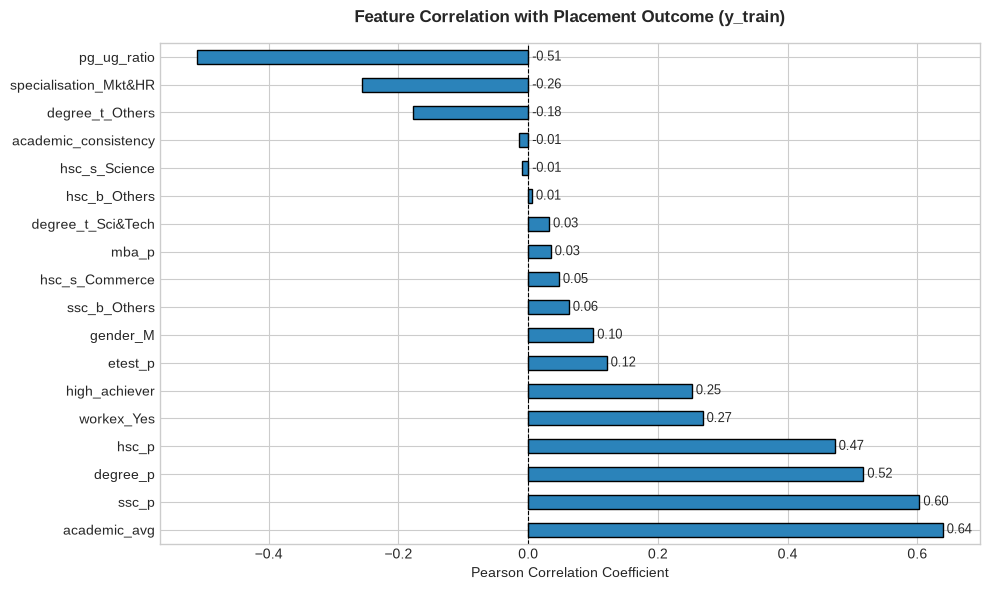

Saved correlation plot: Lab3/outputs/feature_correlation_analysis.png


In [7]:
# 7. Feature Correlation Analysis with Target Variable
# Compute Pearson correlation between all transformed features and training target y_train
correlations = X_train_processed.apply(lambda col: col.corr(y_train)).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
correlations.plot(kind='barh', ax=ax, color='#2b83ba', edgecolor='black')
ax.set_title("Feature Correlation with Placement Outcome (y_train)", fontweight='bold', pad=15)
ax.set_xlabel("Pearson Correlation Coefficient")
ax.axvline(0, color='black', linestyle='--', linewidth=0.8)

for idx, val in enumerate(correlations):
    ax.annotate(f" {val:.2f}",
                (val if val >= 0 else 0, idx),
                va='center', fontsize=9)

plt.tight_layout()
fig_path = OUTPUT_DIR / "feature_correlation_analysis.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved correlation plot: {fig_path}")

--- Top Feature Importance Rankings ---


,Feature,F_Score,F_pValue,Mutual_Info
0,academic_avg,117.364293,3.965620e-21,0.248356
1,ssc_p,97.174838,2.050796e-18,0.217630
2,degree_p,61.900094,4.015882e-13,0.161458
3,pg_ug_ratio,59.899220,8.486150e-13,0.169546
4,hsc_p,48.870893,5.962665e-11,0.135397
5,workex_Yes,13.248726,3.616538e-04,0.099584
6,specialisation_Mkt&HR,11.900531,7.077146e-04,0.000000
7,high_achiever,11.554783,8.419581e-04,0.010155
8,degree_t_Others,5.541352,1.971469e-02,0.000000
9,etest_p,2.524806,1.139266e-01,0.000000


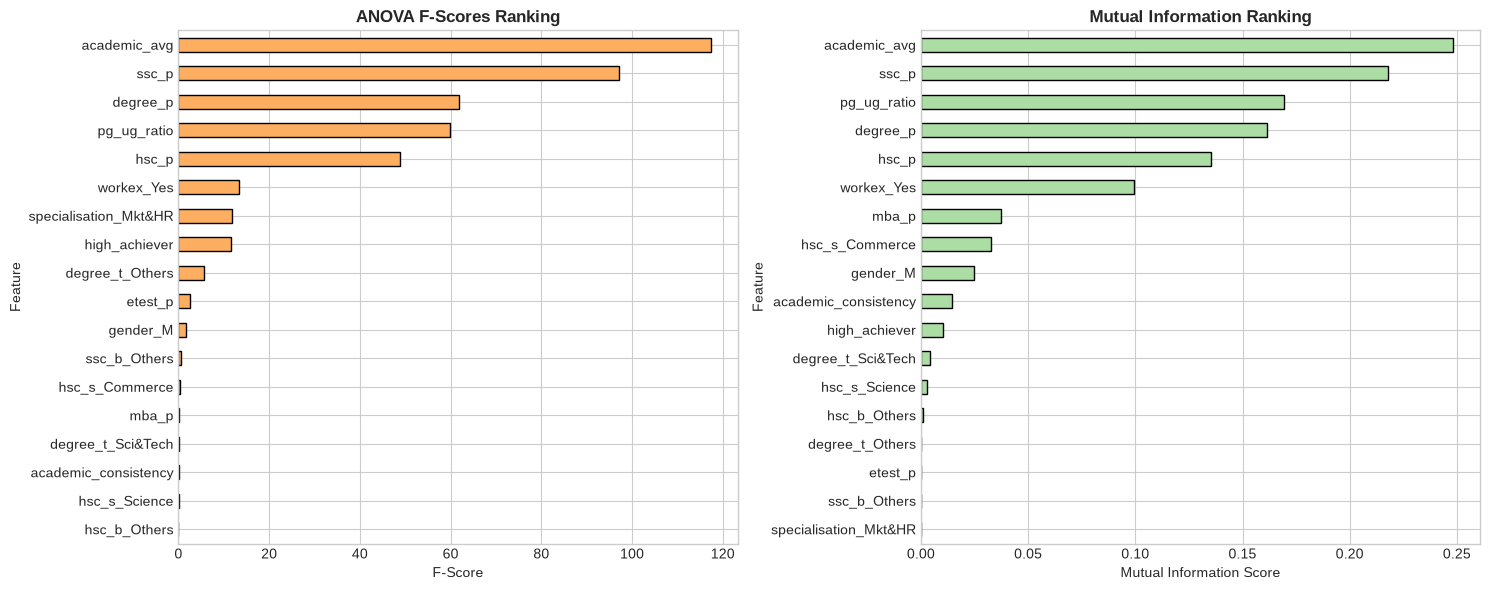

Saved ranking plot: Lab3/outputs/feature_importance_ranking.png


In [8]:
# 8. Statistical Feature Selection: ANOVA F-test and Mutual Information
# Method A: ANOVA F-test (measures linear dependency and between-group variance)
f_scores, f_pvalues = f_classif(X_train_processed, y_train)

# Method B: Mutual Information (measures any non-linear relationship)
mi_scores = mutual_info_classif(X_train_processed, y_train, random_state=42)

ranking_df = pd.DataFrame({
    'Feature': all_feature_names,
    'F_Score': f_scores,
    'F_pValue': f_pvalues,
    'Mutual_Info': mi_scores
}).sort_values(by='F_Score', ascending=False).reset_index(drop=True)

print("--- Top Feature Importance Rankings ---")
display(ranking_df)

# Plot Feature Importance Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ranking_df.sort_values(by='F_Score', ascending=True).plot(
    x='Feature', y='F_Score', kind='barh', ax=ax1, color='#fdae61', edgecolor='black', legend=False
)
ax1.set_title("ANOVA F-Scores Ranking", fontweight='bold')
ax1.set_xlabel("F-Score")

ranking_df.sort_values(by='Mutual_Info', ascending=True).plot(
    x='Feature', y='Mutual_Info', kind='barh', ax=ax2, color='#abdda4', edgecolor='black', legend=False
)
ax2.set_title("Mutual Information Ranking", fontweight='bold')
ax2.set_xlabel("Mutual Information Score")

plt.tight_layout()
fig_path = OUTPUT_DIR / "feature_importance_ranking.png"
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved ranking plot: {fig_path}")

In [9]:
# 9. Final Feature Matrix Shapes and Summary
summary_lines = [
    "=" * 60,
    "LAB 3: FEATURE ENGINEERING PIPELINE SUMMARY",
    "=" * 60,
    f"Random Seed (Reproducibility) : 42",
    f"Train-Test Ratio              : 80% / 20%",
    "",
    "Data Shapes:",
    f"- Raw Features (X)            : {X.shape}",
    f"- Raw Target (y)              : {y.shape}",
    f"- Processed X_train           : {X_train_processed.shape}",
    f"- Processed X_test            : {X_test_processed.shape}",
    f"- Training Labels (y_train)   : {y_train.shape}",
    f"- Testing Labels (y_test)     : {y_test.shape}",
    "",
    "Engineered Features Created   :",
    "1. academic_avg               : Combined mean percentage across school and UG",
    "2. academic_consistency       : Metric of score volatility across degrees",
    "3. pg_ug_ratio                : PG MBA to UG Degree percentage ratio",
    "4. high_achiever              : Multi-tier high achievement boolean indicator",
    "",
    "Top 5 Features by ANOVA F-Score:",
    ranking_df[['Feature', 'F_Score', 'Mutual_Info']].head(5).to_string(index=False),
    "=" * 60
]
summary_text = "\n".join(summary_lines)

print(summary_text)

# Save summary report to outputs directory
summary_path = OUTPUT_DIR / "feature_engineering_summary.txt"
with open(summary_path, 'w', encoding='utf-8') as f:
    f.write(summary_text)

print(f"Saved pipeline summary to: {summary_path}")

LAB 3: FEATURE ENGINEERING PIPELINE SUMMARY
Random Seed (Reproducibility) : 42
Train-Test Ratio              : 80% / 20%

Data Shapes:
- Raw Features (X)            : (215, 16)
- Raw Target (y)              : (215,)
- Processed X_train           : (172, 18)
- Processed X_test            : (43, 18)
- Training Labels (y_train)   : (172,)
- Testing Labels (y_test)     : (43,)

Engineered Features Created   :
1. academic_avg               : Combined mean percentage across school and UG
2. academic_consistency       : Metric of score volatility across degrees
3. pg_ug_ratio                : PG MBA to UG Degree percentage ratio
4. high_achiever              : Multi-tier high achievement boolean indicator

Top 5 Features by ANOVA F-Score:
     Feature    F_Score  Mutual_Info
academic_avg 117.364293     0.248356
       ssc_p  97.174838     0.217630
    degree_p  61.900094     0.161458
 pg_ug_ratio  59.899220     0.169546
       hsc_p  48.870893     0.135397
Saved pipeline summary to: Lab3/outp